In [1]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import contingency_matrix 
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#pd.set_option('display.max_rows', 200)
%matplotlib widget
SMALL_SIZE = 9
MEDIUM_SIZE = 9
BIGGER_SIZE = 14
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rc('figure', autolayout=True)

In [3]:
import glob
path = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/diffusion/v2/reports/"
result_files = glob.glob(path + "/results_summary_*.csv")
df = pd.read_csv(result_files[0])

In [4]:
for file in result_files[1:]:
    df = pd.concat([df, pd.read_csv(file)], ignore_index=True)
df

,ID,cell_types,output,use_perfect_registration,use_perfect_segmentation,teaching_imprecision,canvas_size,mic_spacing,ms_spacing,cell_density,...,m/z 0,STD m/z 0,m/z 1,STD m/z 1,m/z 2,STD m/z 2,m/z 3,STD m/z 3,FPR,ARI
0,8c8c517c-a423-4ba5-83d9-a899b936107a,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.013146,0.019401,0.077079,0.072987,0.127137,0.134591,0.341853,0.405109,0.0,0.862197
1,5571c655-2d43-4dfe-9fd8-3e209e9ab34d,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.020242,0.071057,0.150234,0.107924,0.228857,0.183404,0.418885,0.477079,0.0,0.633747
2,ac5cd9a9-f1c4-4eff-92da-88184a151df0,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.021928,0.029659,0.199822,0.130359,0.282188,0.181376,0.460353,0.517900,0.0,0.579296
3,e09a11c7-c807-48b0-84f0-242de880b183,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.024234,0.029332,0.202350,0.156013,0.271233,0.191247,0.481650,0.539844,0.0,0.310527
4,b47b2163-a28e-41a0-8ffb-313edfb9ecf4,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.037527,0.072988,0.259821,0.162191,0.339995,0.175053,0.487555,0.547473,0.0,0.414167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,bd2d5dce-6383-4ed7-9878-a8f7c1e74c2b,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.052130,0.079867,0.307542,0.155924,0.395549,0.173525,0.532422,0.568133,0.0,0.065717
103,eb76bf8c-362f-4ccd-a109-c7d5581bf48c,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.073064,0.091891,0.364227,0.233910,0.452678,0.269228,0.554932,0.595783,0.0,0.183942
104,ddc26305-3315-4dea-9a31-3f48b7e3fd02,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.058269,0.057831,0.330458,0.184224,0.406958,0.196375,0.544521,0.596869,0.0,0.207165
105,442f63f5-47c3-49e9-baae-d0f4e4f1ec30,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.008054,0.012257,0.008374,0.012809,0.014709,0.034496,0.045116,0.089075,0.0,0.675878


In [5]:
df['remove_ambiguous']

0      False
1      False
2      False
3      False
4      False
       ...  
102    False
103    False
104    False
105    False
106    False
Name: remove_ambiguous, Length: 107, dtype: bool

In [6]:
mean_diffusion = df.groupby('diffusion_total_time')[['diffusion_total_time', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].mean()
std_diffusion = df.groupby('diffusion_total_time')[['diffusion_total_time', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].std()

<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not w

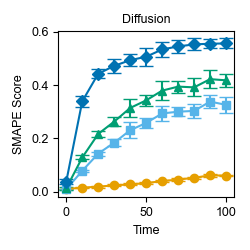

In [7]:
colors = ['#E69F00', '#56B4E9', '#009E73', '#0072B2']
markers = ['o', 's', '^', 'D']
labels = ['$\mathit{m/z}$ 1', '$\mathit{m/z}$ 2', '$\mathit{m/z}$ 3', '$\mathit{m/z}$ 4']
plt.figure(figsize=(2.5,2.5))
for i, mz in enumerate(['m/z 0', 'm/z 1', 'm/z 2', 'm/z 3']):
    plt.errorbar(mean_diffusion['diffusion_total_time'], mean_diffusion[mz], yerr=std_diffusion[mz], label=labels[i], color=colors[i], marker=markers[i], fmt='o-', capsize=5)
plt.xlabel('Time')
plt.ylabel('SMAPE Score')
plt.title('Diffusion')
plt.tight_layout()
#plt.legend()
plt.tight_layout()
plt.savefig(path + "evaluation/diffusion_total_time_results.png", dpi=600)
plt.show()

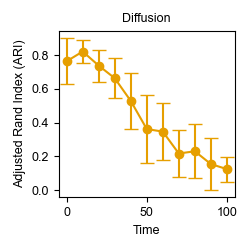

In [8]:
plt.figure(figsize=(2.5,2.5))
plt.errorbar(mean_diffusion['diffusion_total_time'], mean_diffusion['ARI'], yerr=std_diffusion['ARI'], label='K-Means Clustering', color=colors[0], fmt='o-', capsize=5)
plt.xlabel('Time')
plt.ylabel('Adjusted Rand Index (ARI)')
plt.title('Diffusion')
#plt.legend()
plt.tight_layout()
plt.savefig(path + "evaluation/diffusion_total_time_ARI_results.png", dpi=600)
plt.show()